# Exploratory Data Analysis (EDA) & Data Preparation

**Dataset:** Credit Score of customers with 8 consecutive month period data (`Credit_score_cleaned_data.csv`, Kaggle Dataset)

**Target variable:** `Credit_Score` (31 features)


## Dataset Overview

**What it is**. 

**Reason of choice**.

**EDA pipeline**.

**Reproducibility**.

## Download dataset

Uncomment this if the dataset is not downloaded in the folder

In [1]:
# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("ayushsharma0812/dataset-for-credit-score-classification")

# print("Path to dataset files:", path)

## Setup
Import packages, set one consistent plot style and define constant reused across the notebook

In [2]:
# Setup: Libraries and global plot style, and constants
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

# One consistent, readable style for every figure

sns.set_theme(style='whitegrid', context="notebook", font_scale = 1.0)
plt.rcParams.update({
    "figure.figsize":(10,6),
    "figure.dpi":100,
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelsize": 12
})

pd.set_option('display.max_rows', None)

print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)
print("Setup completed successfully.")

pandas 3.0.5 | numpy 2.4.6 | seaborn 0.13.2
Setup completed successfully.


## Load datasets

In [3]:
file_path = Path(r"./Dataset/Credit_score_cleaned_data.csv")
if not file_path.exists():
    raise FileNotFoundError(
        f"{file_path} not found. Download it from commented above codeblock from kaggle."
    )
df = pd.read_csv(file_path)
df.columns = df.columns.str.lower()

# Set options to display full columns
pd.set_option('display.max_columns', None)

In [4]:
print(f"Dataset shape: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Dataset Overview: {df.info()}")
print(f"First 5 rows: {df.head(5)}")

Dataset shape: 100000 rows x 32 columns
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 32 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   customer_id               100000 non-null  str    
 1   age                       100000 non-null  int64  
 2   occupation                100000 non-null  str    
 3   annual_income             100000 non-null  float64
 4   monthly_inhand_salary     100000 non-null  float64
 5   num_bank_accounts         100000 non-null  int64  
 6   num_credit_card           100000 non-null  int64  
 7   interest_rate             100000 non-null  float64
 8   num_of_loan               100000 non-null  int64  
 9   delay_from_due_date       100000 non-null  int64  
 10  num_of_delayed_payment    100000 non-null  int64  
 11  changed_credit_limit      100000 non-null  float64
 12  num_credit_inquiries      100000 non-null  int64  
 13  credit_mix      

## Data types and data dictionary

The table below documents both the storage type and the real meaning of each column.

In [5]:
data_dictionary = {
    "customer_id": ("Nominal","Unique identification of a customer"),
    "age": ("Ratio", "Age of the customer"),
    "occupation": ("Nominal", "Occupation of the customer"),
    "annual_income": ("Ratio", "Annual income of the customer"),
    "monthly_inhand_salary": ("Ratio", "Monthly inhand salary of the customer"),
    "num_bank_accounts": ("Ratio", "Number of bank accounts the customer holds"),
    "num_credit_card": ("Ratio", "Number of credit cards held by the customer"),
    "interest_rate": ("Ratio", "Interest rate on credit card"),
    "num_of_loan": ("Ratio", "Number of loans taken"),
    "delay_from_due_date": ("Ratio", "Average number of days delayed from the payment due date"),
    "num_of_delayed_payment": ("Ratio", "Number of payments delayed"),
    "changed_credit_limit": ("Ratio", "Percentage change in credit card limit"),
    "num_credit_inquiries": ("Ratio", "Number of credit card inquiries made by lenders on customer"),
    "credit_mix": ("Ordinal", "Type of the mix of credits that the customer has: (Bad/Standard/Good)"),
    "outstanding_debt": ("Ratio", "Remaining debt to be paid (in USD)"),
    "credit_utilization_ratio": ("Ratio", "Utilization ratio of credit card"),
    "credit_history_age": ("Ratio", "The age of credit history of the customer in months"),
    "payment_of_min_amount": ("Nominal", "Whether minimum amount was paid by the customer or not: (Yes/No)"),
    "total_emi_per_month": ("Ratio", "Monthly EMI payments (in USD)"),
    "amount_invested_monthly": ("Ratio", "Monthly amount invested by the customer (in USD)"),
    "payment_behaviour": ("Ordinal", "Payment behaviour of the customer: (Low/High)_spent_(Small/Medium/Large)_value_payments"),
    "monthly_balance": ("Ratio", "Monthly balance amount of the customer (in USD)"),
    "last_loan_9": ("Nominal", "Latest loan taken"),
    "last_loan_8": ("Nominal", "Second latest loan taken"),
    "last_loan_7": ("Nominal", "Third latest loan taken"),
    "last_loan_6": ("Nominal", "Fourth latest loan taken"),
    "last_loan_5": ("Nominal", "Fifth latest loan taken"),
    "last_loan_4": ("Nominal", "Sixth latest loan taken"),
    "last_loan_3": ("Nominal", "Seventh latest loan taken"),
    "last_loan_2": ("Nominal", "Eighth latest loan taken"),
    "last_loan_1": ("Nominal", "Ninth latest loan taken"),
    "credit_score": ("Nominal", "Credit score assigned to the customer for given month")
}

dtype_table = pd.DataFrame({
    "Pandas dtype": df.dtypes.astype(str),
    "Unique values": df.nunique(),
    "Variable type": [data_dictionary[c][0] for c in df.columns],
    "Meaning/ Unit": [data_dictionary[c][1] for c in df.columns]
})

dtype_table

,Pandas dtype,Unique values,Variable type,Meaning/ Unit
customer_id,str,12500,Nominal,Unique identification of a customer
age,int64,43,Ratio,Age of the customer
occupation,str,15,Nominal,Occupation of the customer
annual_income,float64,12488,Ratio,Annual income of the customer
monthly_inhand_salary,float64,13233,Ratio,Monthly inhand salary of the customer
num_bank_accounts,int64,12,Ratio,Number of bank accounts the customer holds
num_credit_card,int64,12,Ratio,Number of credit cards held by the customer
interest_rate,float64,34,Ratio,Interest rate on credit card
num_of_loan,int64,10,Ratio,Number of loans taken
delay_from_due_date,int64,73,Ratio,Average number of days delayed from the paymen...


## Basic statistical summary

In [6]:
# Basic statistical summary - numerical columns
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
age,100000.0,33.309,10.765,14.000,24.000,33.000,42.000,56.000
annual_income,100000.0,50505.123,38299.422,7005.930,19342.972,36999.705,71683.470,179987.280
monthly_inhand_salary,100000.0,4198.772,3187.494,303.645,1626.762,3096.378,5961.745,15204.633
num_bank_accounts,100000.0,5.369,2.593,0.000,3.000,5.000,7.000,11.000
num_credit_card,100000.0,5.534,2.067,0.000,4.000,5.000,7.000,11.000
interest_rate,100000.0,14.532,8.741,1.000,7.000,13.000,20.000,34.000
num_of_loan,100000.0,3.533,2.446,0.000,2.000,3.000,5.000,9.000
delay_from_due_date,100000.0,21.069,14.860,-5.000,10.000,18.000,28.000,67.000
num_of_delayed_payment,100000.0,13.329,6.269,0.000,9.000,14.000,18.000,28.000
changed_credit_limit,100000.0,10.389,6.784,-6.490,5.340,9.400,14.850,36.970


There is a suspicious minimum value in `total_emi_per_month` which should not contain negative value.

In [7]:
# Basic statistical summary - categorical columns
cat_summary = df.select_dtypes(exclude=np.number).describe().T
cat_summary["top %"] = (cat_summary["freq"].astype(int) / len(df) * 100).round(1)
cat_summary

,count,unique,top,freq,top %
customer_id,100000,12500,CUS_0x98ed,8,0.0
occupation,100000,15,Lawyer,7096,7.1
credit_mix,100000,3,Standard,45848,45.8
payment_of_min_amount,100000,2,Yes,59432,59.4
payment_behaviour,100000,6,Low_spent_Small_value_payments,36650,36.6
last_loan_9,100000,10,No Loan,96144,96.1
last_loan_8,100000,10,No Loan,92808,92.8
last_loan_7,100000,10,No Loan,85128,85.1
last_loan_6,100000,10,No Loan,76984,77.0
last_loan_5,100000,10,No Loan,69456,69.5


## Inital missing value check

In [8]:
print("Total missing cells:", int(df.isnull().sum().sum()))
df.isnull().sum().to_frame("Missing count")

Total missing cells: 0


,Missing count
customer_id,0
age,0
occupation,0
annual_income,0
monthly_inhand_salary,0
num_bank_accounts,0
num_credit_card,0
interest_rate,0
num_of_loan,0
delay_from_due_date,0


## Overall about Observations


#### Explore about qualitative variables

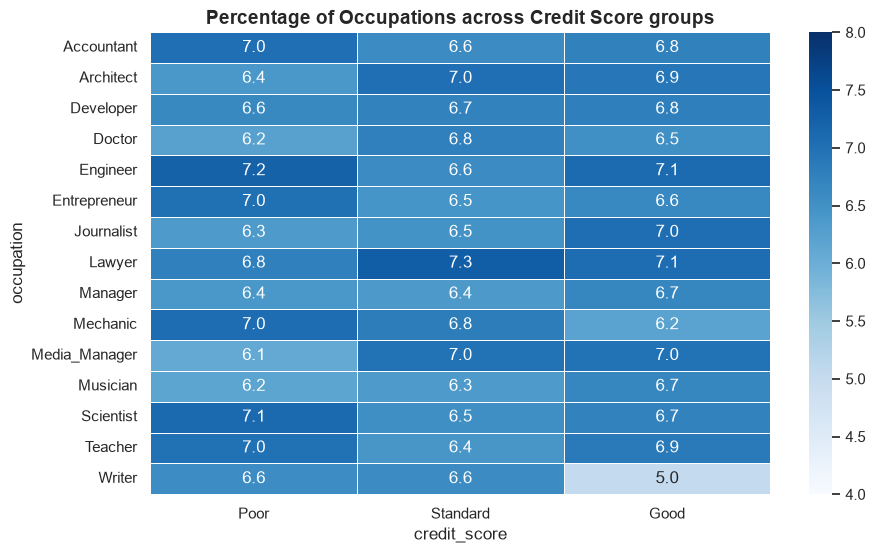

In [9]:
cross_tab_per_ocp = pd.crosstab(index = df['occupation'], columns = df['credit_score'],
                            normalize = 'columns')[['Poor', 'Standard', 'Good']]*100
sns.heatmap(data = cross_tab_per_ocp, annot = True, cmap = 'Blues', vmin = 4, vmax = 8, fmt = '.1f', linewidth = 0.5)
plt.title("Percentage of Occupations across Credit Score groups")
plt.show()

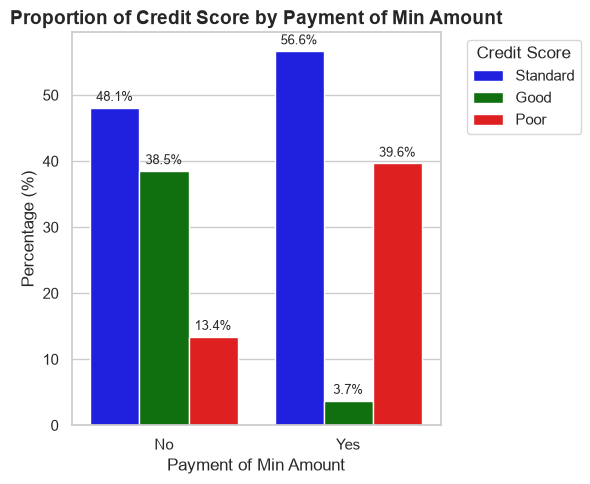

In [10]:
df_prop = df.groupby("payment_of_min_amount")['credit_score'].value_counts(normalize=True).rename('proportion').reset_index()
df_prop['percentage'] = df_prop['proportion']*100
plt.figure(figsize = (6,5))
colors = {'Standard': 'Blue', 'Good': 'Green', 'Poor': 'Red'}
ax = sns.barplot(data = df_prop, x = 'payment_of_min_amount', y = 'percentage', hue = 'credit_score', palette = colors)
for container in ax.containers:
      ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)

plt.title("Proportion of Credit Score by Payment of Min Amount")
plt.xlabel("Payment of Min Amount")
plt.ylabel("Percentage (%)")
plt.legend(title = 'Credit Score', bbox_to_anchor = (1.05,1), loc = 'upper left')
plt.tight_layout()
plt.show()

Value counts for column credit_score


,credit_score,count
0,Good,17828
1,Poor,28998
2,Standard,53174


Value counts for column credit_mix


,credit_mix,count
0,Bad,23768
1,Good,30384
2,Standard,45848


Value counts for column payment_behaviour


,payment_level,payment_volume,count
0,High payment,Large payment,15439
1,High payment,Medium payment,20812
2,High payment,Small payment,8253
3,Low payment,Large payment,7354
4,Low payment,Medium payment,11492
5,Low payment,Small payment,36650


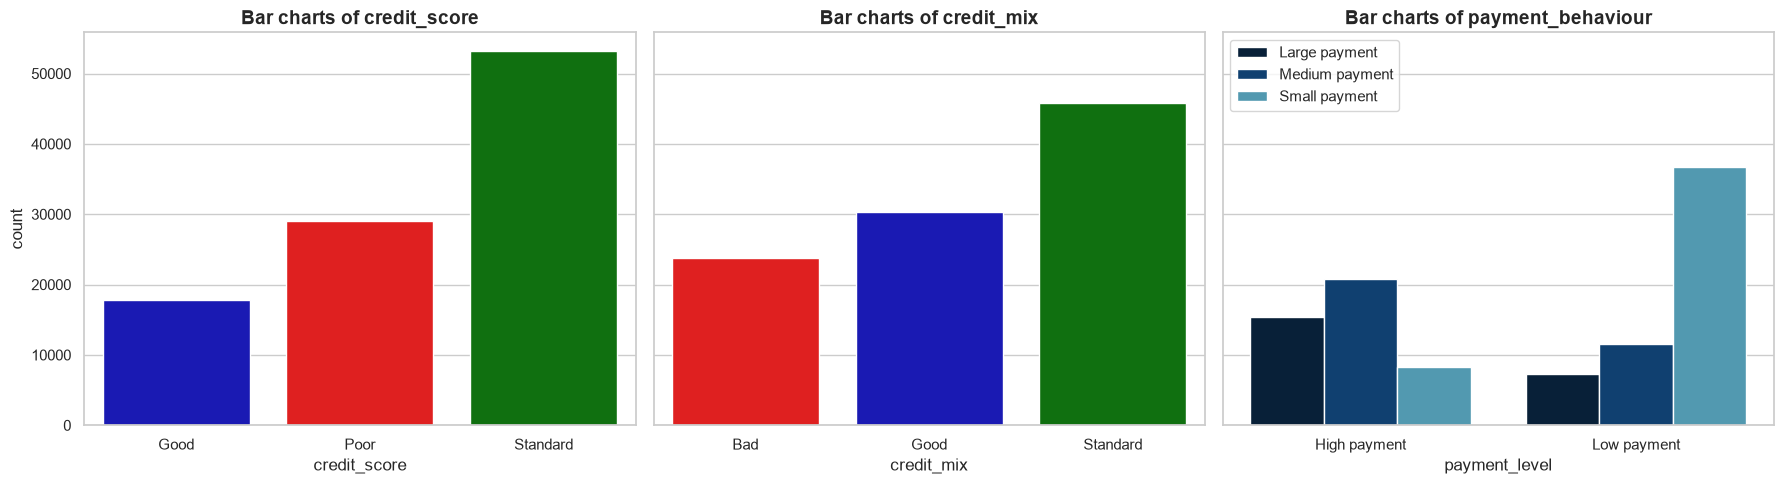

In [11]:
# Add 2 more columns for payment_behaviour
df['payment_level'] = 'default'
df.loc[df['payment_behaviour'].str.contains('Low', case = False, na = False), 'payment_level'] = 'Low payment'
df.loc[df['payment_behaviour'].str.contains('High',case = False, na = False), 'payment_level'] = 'High payment'

df['payment_volume'] = 'default'
df.loc[df['payment_behaviour'].str.contains('Small', case = False, na = False), 'payment_volume'] = 'Small payment'
df.loc[df['payment_behaviour'].str.contains('Medium', case = False, na = False), 'payment_volume'] = 'Medium payment'
df.loc[df['payment_behaviour'].str.contains('Large', case = False, na = False), 'payment_volume'] = 'Large payment'

# Setup layout for ordinal variables
ordinal_cols = ['credit_score','credit_mix', 'payment_behaviour']
fig, axes = plt.subplots(1,3, figsize = (18,5), sharey = True)
color_score = {'Standard': 'green', 'Poor': 'red', 'Bad': 'red', 'Good': 'mediumblue'}
# Create bar charts
credit_score_count = df['credit_score'].value_counts().sort_values().reset_index()
sns.barplot(data = credit_score_count, y = 'count', x = 'credit_score', ax = axes[0], hue = 'credit_score', palette = color_score)

credit_mix_count = df['credit_mix'].value_counts().sort_values().reset_index()
sns.barplot(data = credit_mix_count, y = 'count', x = 'credit_mix', ax = axes[1], hue = 'credit_mix', palette = color_score)

df_payment_group = df.groupby(['payment_level','payment_volume']).size().reset_index(name = 'count')
sns.barplot(data = df_payment_group, x = 'payment_level', y = 'count', hue = 'payment_volume', ax = axes[2], palette = 'ocean')

# Set labels and display grouped tables for charts
ordinal_grouped_count_table = [credit_score_count, credit_mix_count, df_payment_group]

for ax, col, table in zip(axes,ordinal_cols, ordinal_grouped_count_table):
    ax.set_axisbelow(True)
    ax.set_title(f'Bar charts of {col}')
    print(f'Value counts for column {col}')
    display(table)

plt.legend(loc = 'upper left')
plt.tight_layout()
plt.show()

#### Explore about quantitative variables

In [12]:
# Statistical outliers (1.5 x IQR rule) on the cleaned data
from numpy import float64
dis_ratio_var = ['age', 'num_bank_accounts','num_credit_card','num_of_loan','delay_from_due_date','num_of_delayed_payment',
                    'num_credit_inquiries','credit_history_age']

con_ratio_var = ['annual_income','monthly_inhand_salary','interest_rate','changed_credit_limit','outstanding_debt',
                'credit_utilization_ratio','total_emi_per_month','amount_invested_monthly','monthly_balance']

numeric_cols = dis_ratio_var + con_ratio_var
rows = []
for col in numeric_cols:
    q1, q3 = df[col].quantile([0.25,0.75])
    iqr = q3 - q1
    low, high = q1 - iqr*1.5, q3 + iqr*1.5
    n_outlier = int(((df[col] <= low) | (df[col] >= high)).sum())
    rows.append([col, round(iqr,2), round(low,2), round(high,2), n_outlier, 
                round((n_outlier/len(df))*100,1), df[col].min(), df[col].max()])

outlier_table = pd.DataFrame(rows, columns = ["Features", "IQR width", "(1.5)IQR lower", "(1.5)IQR upper",
                                                "Outliers", "Outliers (%)", "Min", "Max"]).set_index("Features")

outlier_table

,IQR width,(1.5)IQR lower,(1.5)IQR upper,Outliers,Outliers (%),Min,Max
Features,,,,,,,
age,18.00,-3.00,69.00,0,0.0,14.000000,56.000000
num_bank_accounts,4.00,-3.00,13.00,0,0.0,0.000000,11.000000
num_credit_card,3.00,-0.50,11.50,0,0.0,0.000000,11.000000
num_of_loan,3.00,-2.50,9.50,0,0.0,0.000000,9.000000
delay_from_due_date,18.00,-17.00,55.00,4562,4.6,-5.000000,67.000000
num_of_delayed_payment,9.00,-4.50,31.50,0,0.0,0.000000,28.000000
num_credit_inquiries,5.00,-4.50,15.50,765,0.8,0.000000,17.000000
credit_history_age,158.00,-93.00,539.00,0,0.0,1.000000,404.000000
annual_income,52340.50,-59167.77,150194.22,2000,2.0,7005.930000,179987.280000


### Check on suspicious values of `total_emi_per_month`

In [13]:
# Check on the percentiles
print("Statistical check: \n")
statistical_check = (df['total_emi_per_month'].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99])).to_frame()
print(statistical_check)

negative_counts = (df['total_emi_per_month'] < 0).sum()
print(f"\nContaining negative values: {negative_counts} rows")

print(df[df['total_emi_per_month'] < 0]['total_emi_per_month'].value_counts())

Statistical check: 

       total_emi_per_month
count        100000.000000
mean             88.209450
std              83.244703
min              -1.000000
1%                0.000000
5%                0.000000
50%              61.541296
95%             264.306822
99%             330.579688
max             357.406068

Containing negative values: 24 rows
total_emi_per_month
-1.000000    9
-0.004484    3
-0.013257    3
-0.026001    2
-0.009900    2
-0.032644    2
-0.011947    1
-0.016646    1
-0.016846    1
Name: count, dtype: int64


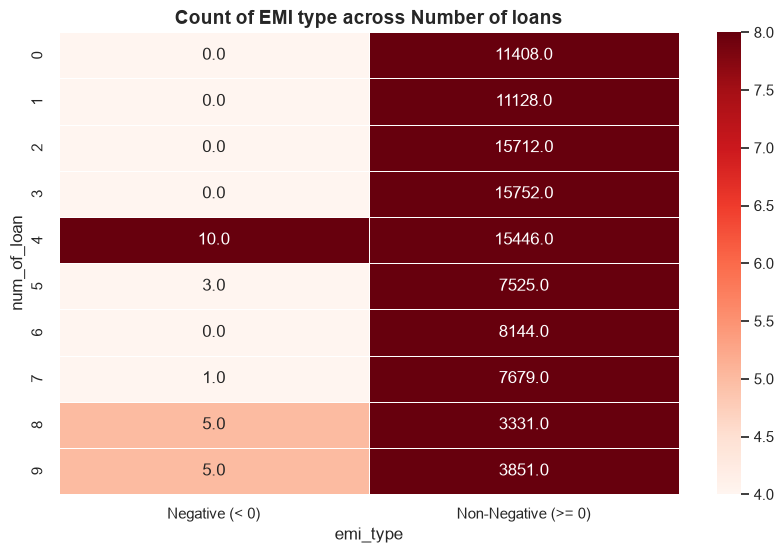

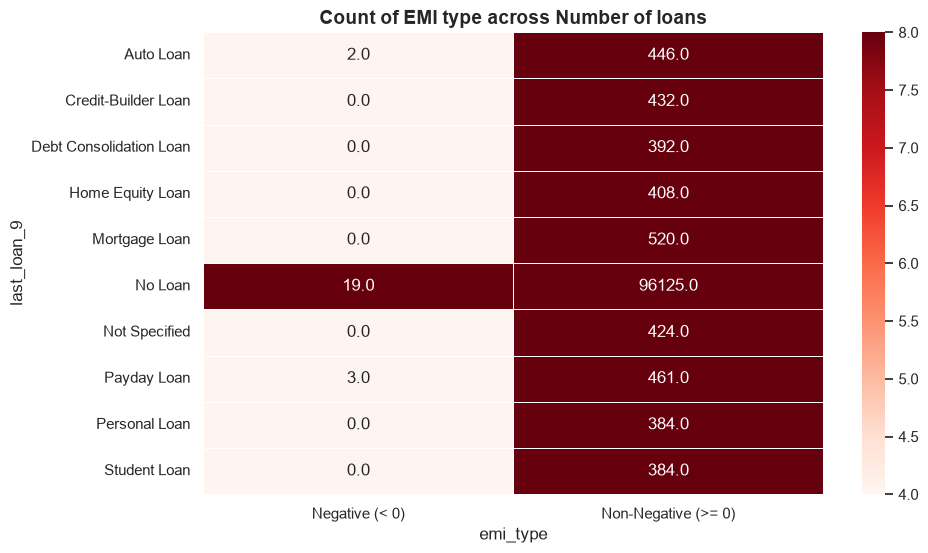

In [ ]:
df['emi_type'] = np.where(df['total_emi_per_month'] < 0,'Negative (< 0)', 'Non-Negative (>= 0)')
cross_tab_ne_emi = pd.crosstab(index = df['num_of_loan'], columns = df['emi_type'])
sns.heatmap(data=cross_tab_ne_emi, annot = True, cmap = 'Reds', vmin = 4, vmax = 8, fmt = '.1f', linewidth = 0.5)
plt.title("Count of EMI type across Number of loans")
plt.show()


In [ ]:
print("\n Customers having invalid emi type")
cus_emi = (df_mismatched.groupby('emi_type')['customer_id'].nunique()).to_frame()
print(cus_emi)

negative_emi_customers = df_mismatched[df_mismatched['total_emi_per_month'] < 0]['customer_id'].unique()
positive_emi_customers = df_mismatched[df_mismatched['total_emi_per_month'] >= 0]['customer_id'].unique()

print(f"\nVí dụ 5 customer_id thuộc nhóm lệch do EMI âm: {negative_emi_customers[:5]}")
print(f"Ví dụ 5 customer_id thuộc nhóm lệch dù EMI dương: {positive_emi_customers[:5]}")


 Customers having invalid emi type
                     customer_id
emi_type                        
Negative (< 0)                10
Non-Negative (>= 0)        12480

Ví dụ 5 customer_id thuộc nhóm lệch do EMI âm: <StringArray>
['CUS_0xe6c', 'CUS_0x8f68', 'CUS_0xa01f', 'CUS_0xb518', 'CUS_0x7b47']
Length: 5, dtype: str
Ví dụ 5 customer_id thuộc nhóm lệch dù EMI dương: <StringArray>
['CUS_0x98ed', 'CUS_0x36b4', 'CUS_0x105b', 'CUS_0x4c4a', 'CUS_0x612f']
Length: 5, dtype: str


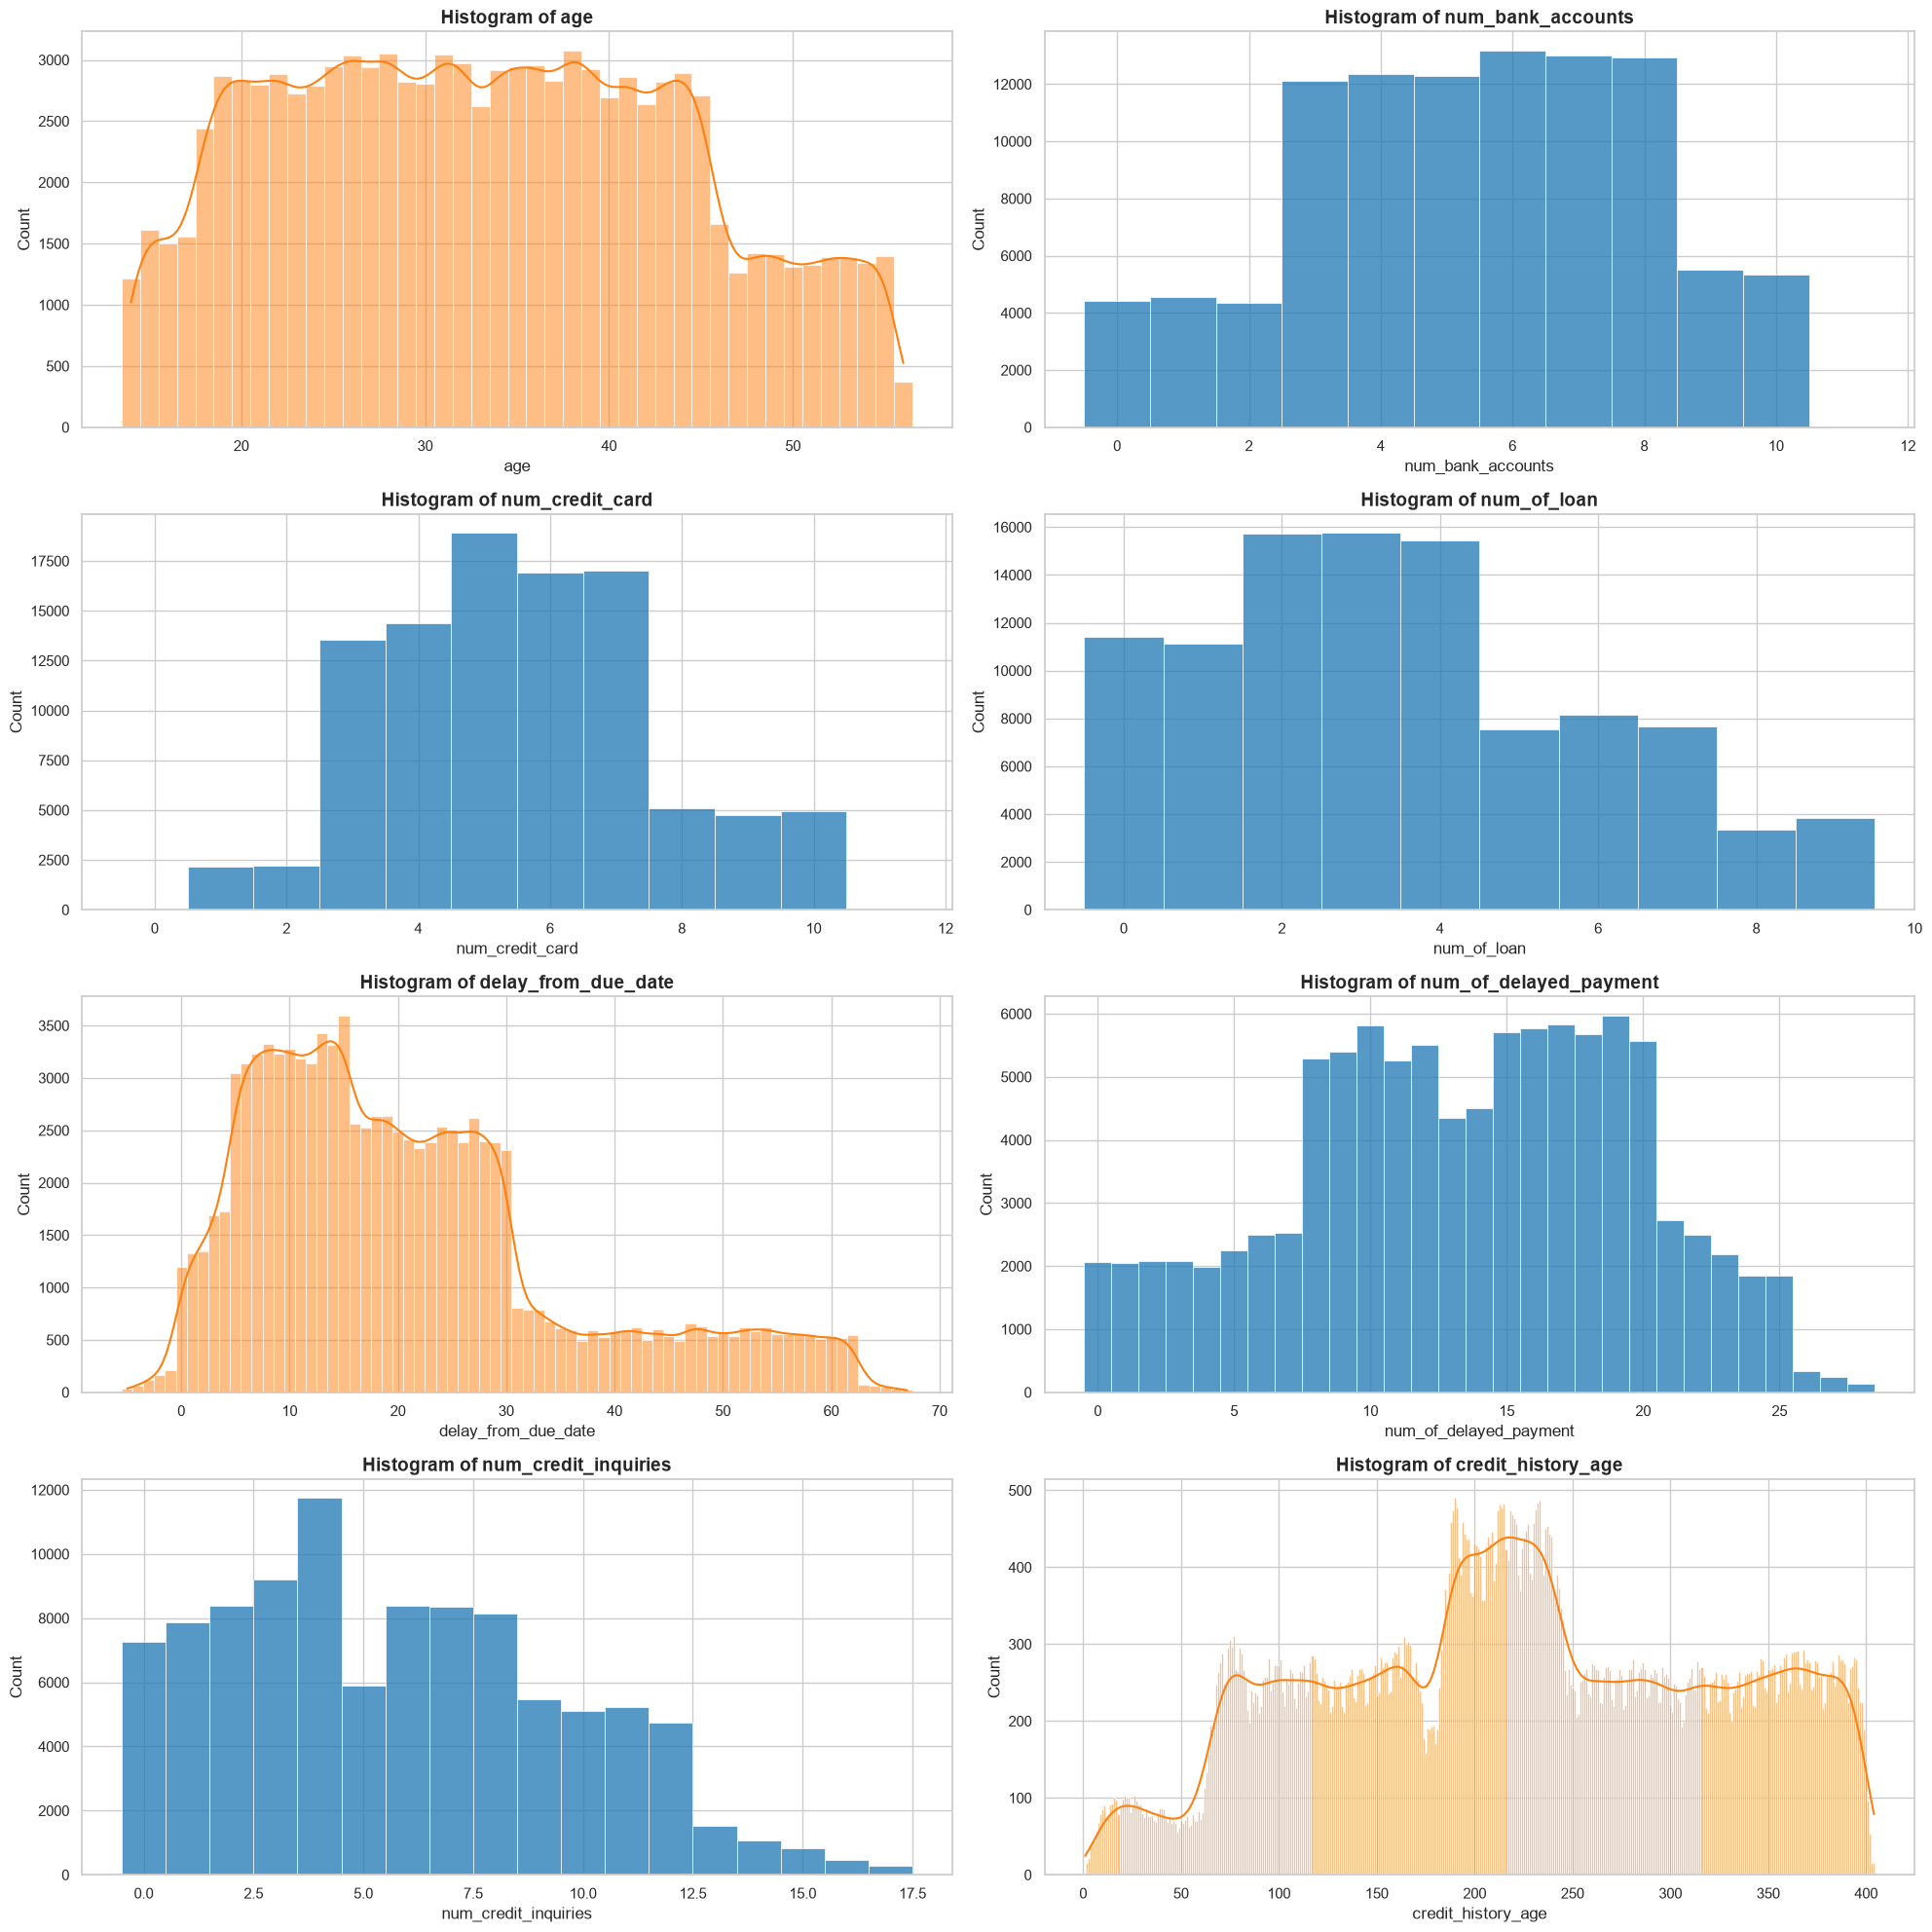

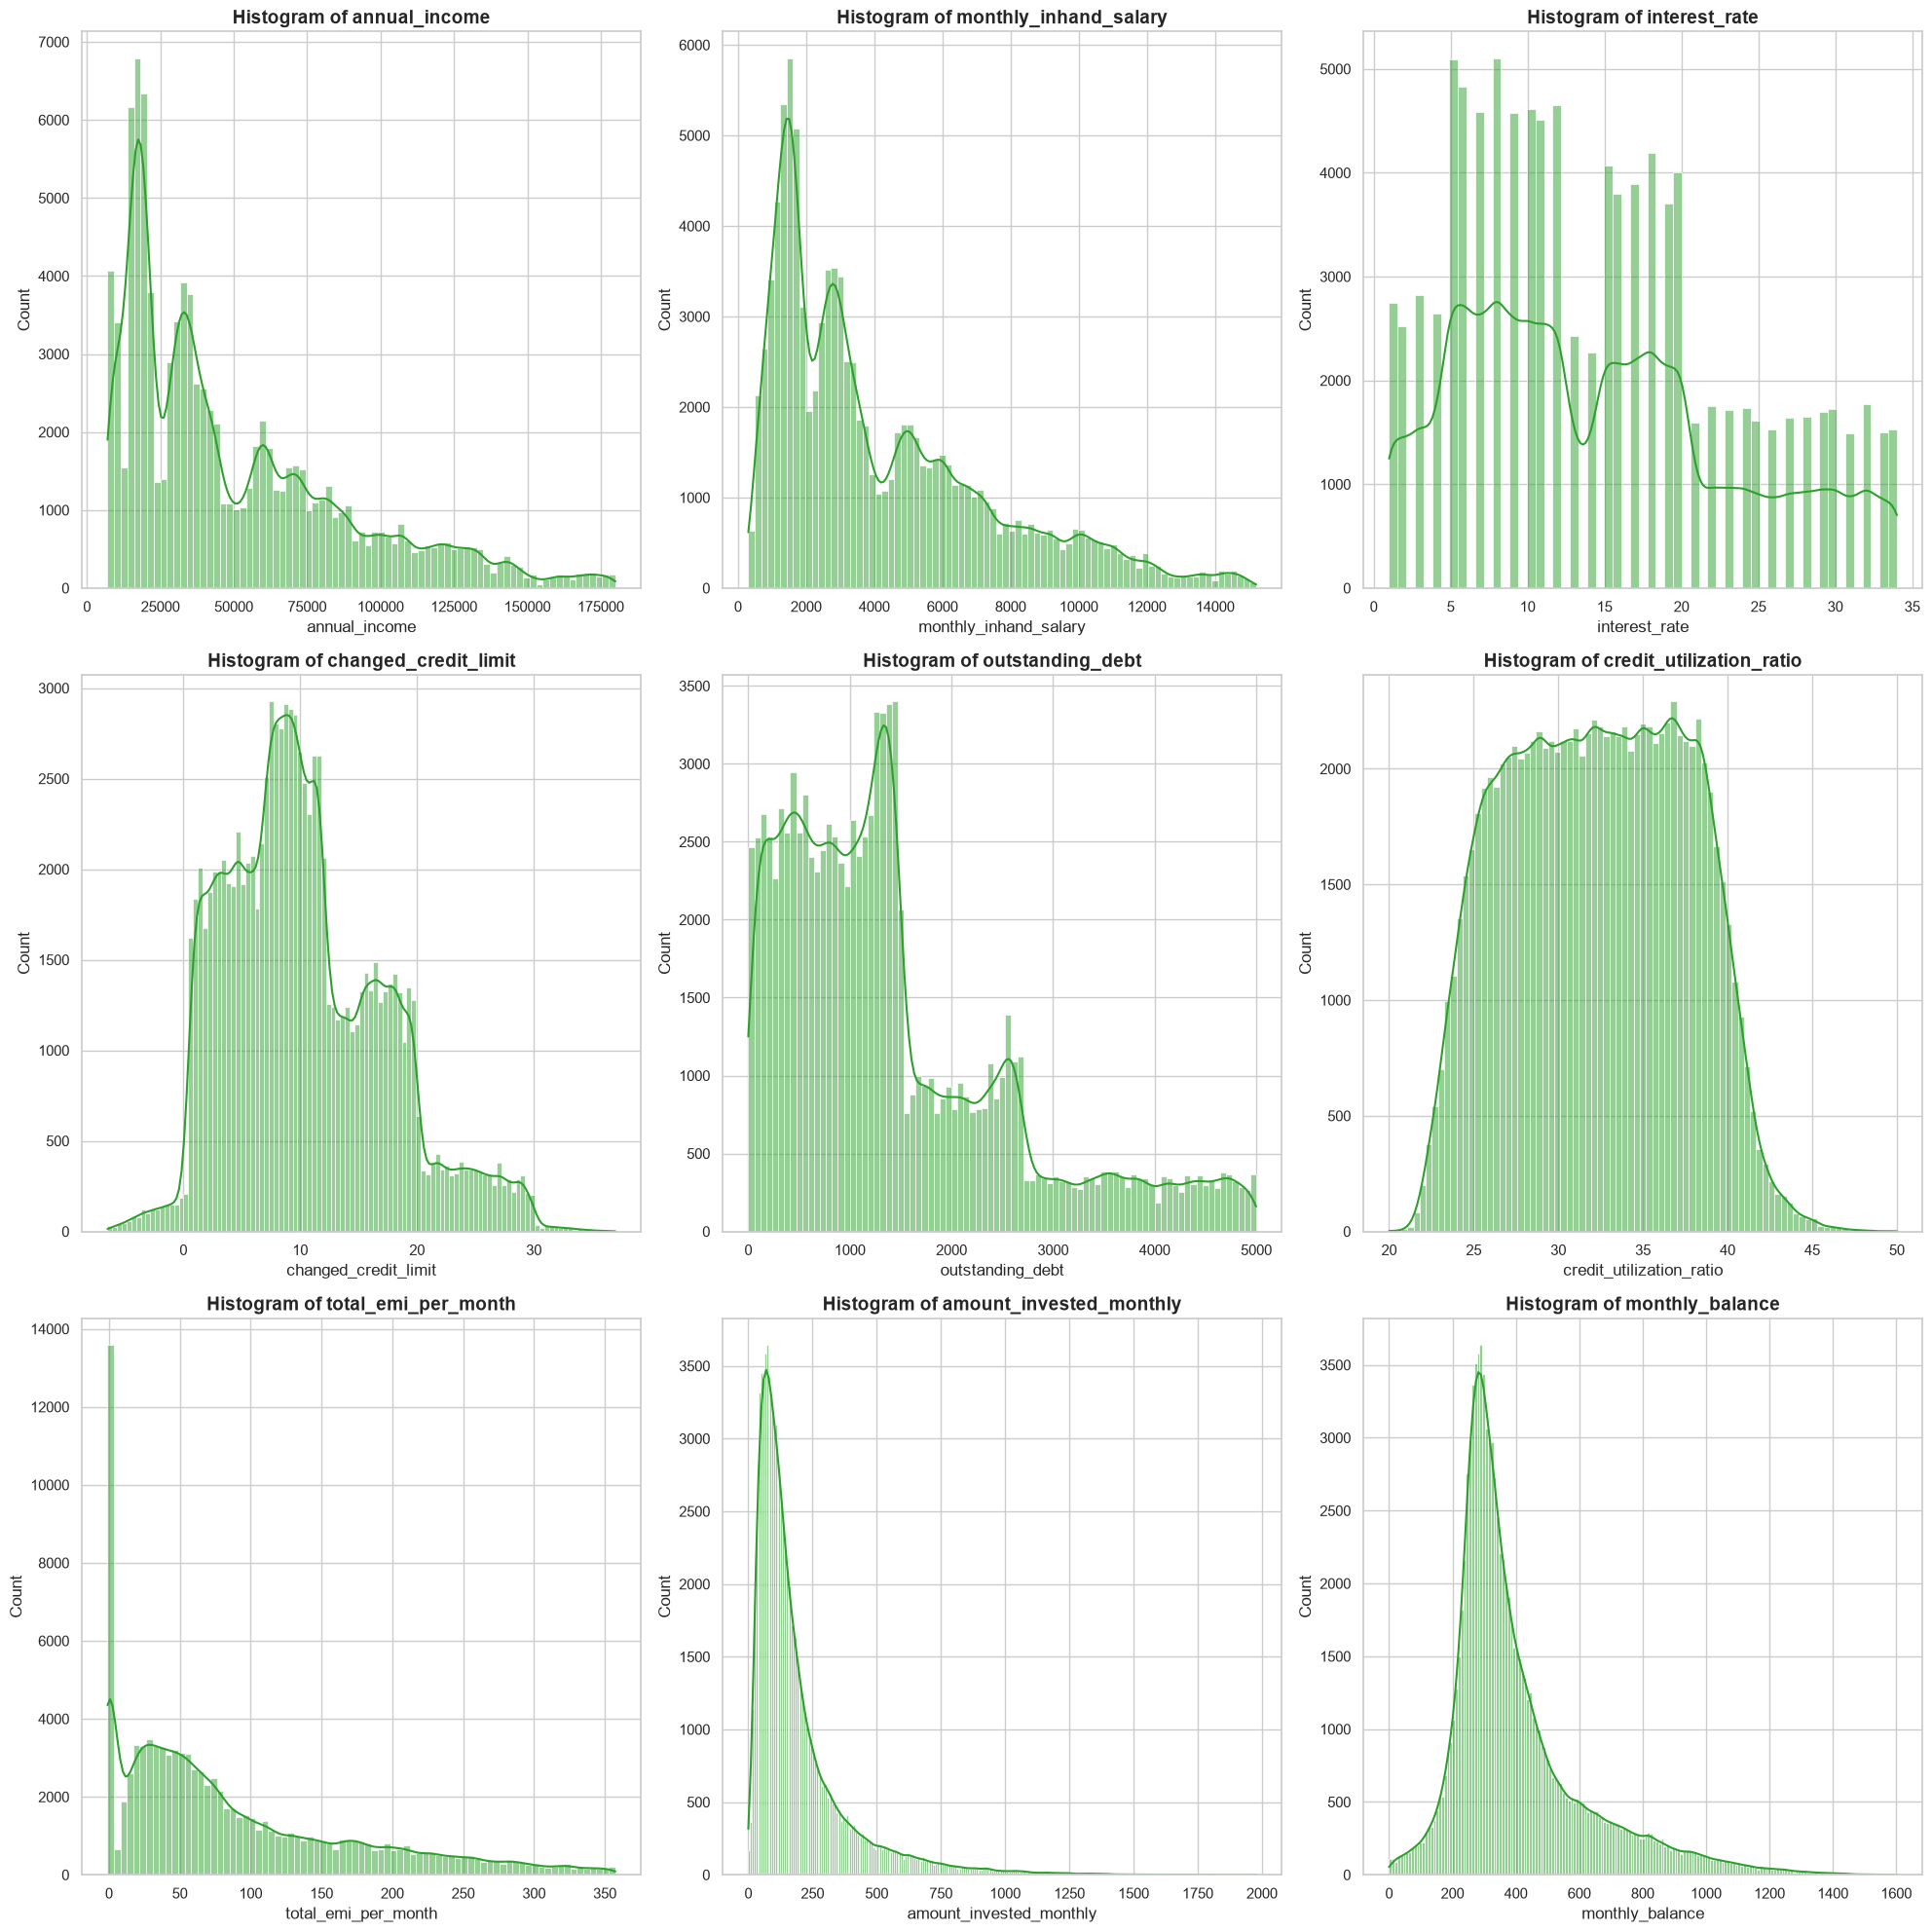

In [ ]:
# Draw histogram for 8 discrete ratio variables
fig, axes = plt.subplots(4,2,figsize = (20,20))
axes = axes.flatten()

for var, ax in zip(dis_ratio_var, axes):
    include_num = 'num' in var.lower()
    kde_status = False if include_num else True
    color =  'tab:blue' if include_num else 'tab:orange'
    sns.histplot(data = df, x = var, kde = kde_status, stat = 'count', discrete = True, color = color, kde_kws = {'bw_adjust': 0.7}, edgecolor = 'w', linewidth = 0.5, ax = ax)
    ax.set_title(f'Histogram of {var}')

plt.tight_layout()

# Draw histogram for 9 continuous ratio variables
fig, axes = plt.subplots(3,3,figsize = (20,20))
axes = axes.flatten()

for var, ax in zip(con_ratio_var, axes):
    sns.histplot(data = df, x = var, kde = True, stat = 'count', kde_kws = {'bw_adjust':0.7}, color = 'tab:green', edgecolor = 'w', linewidth = 0.5, ax = ax)
    ax.set_title(f'Histogram of {var}')

plt.tight_layout()
plt.show()

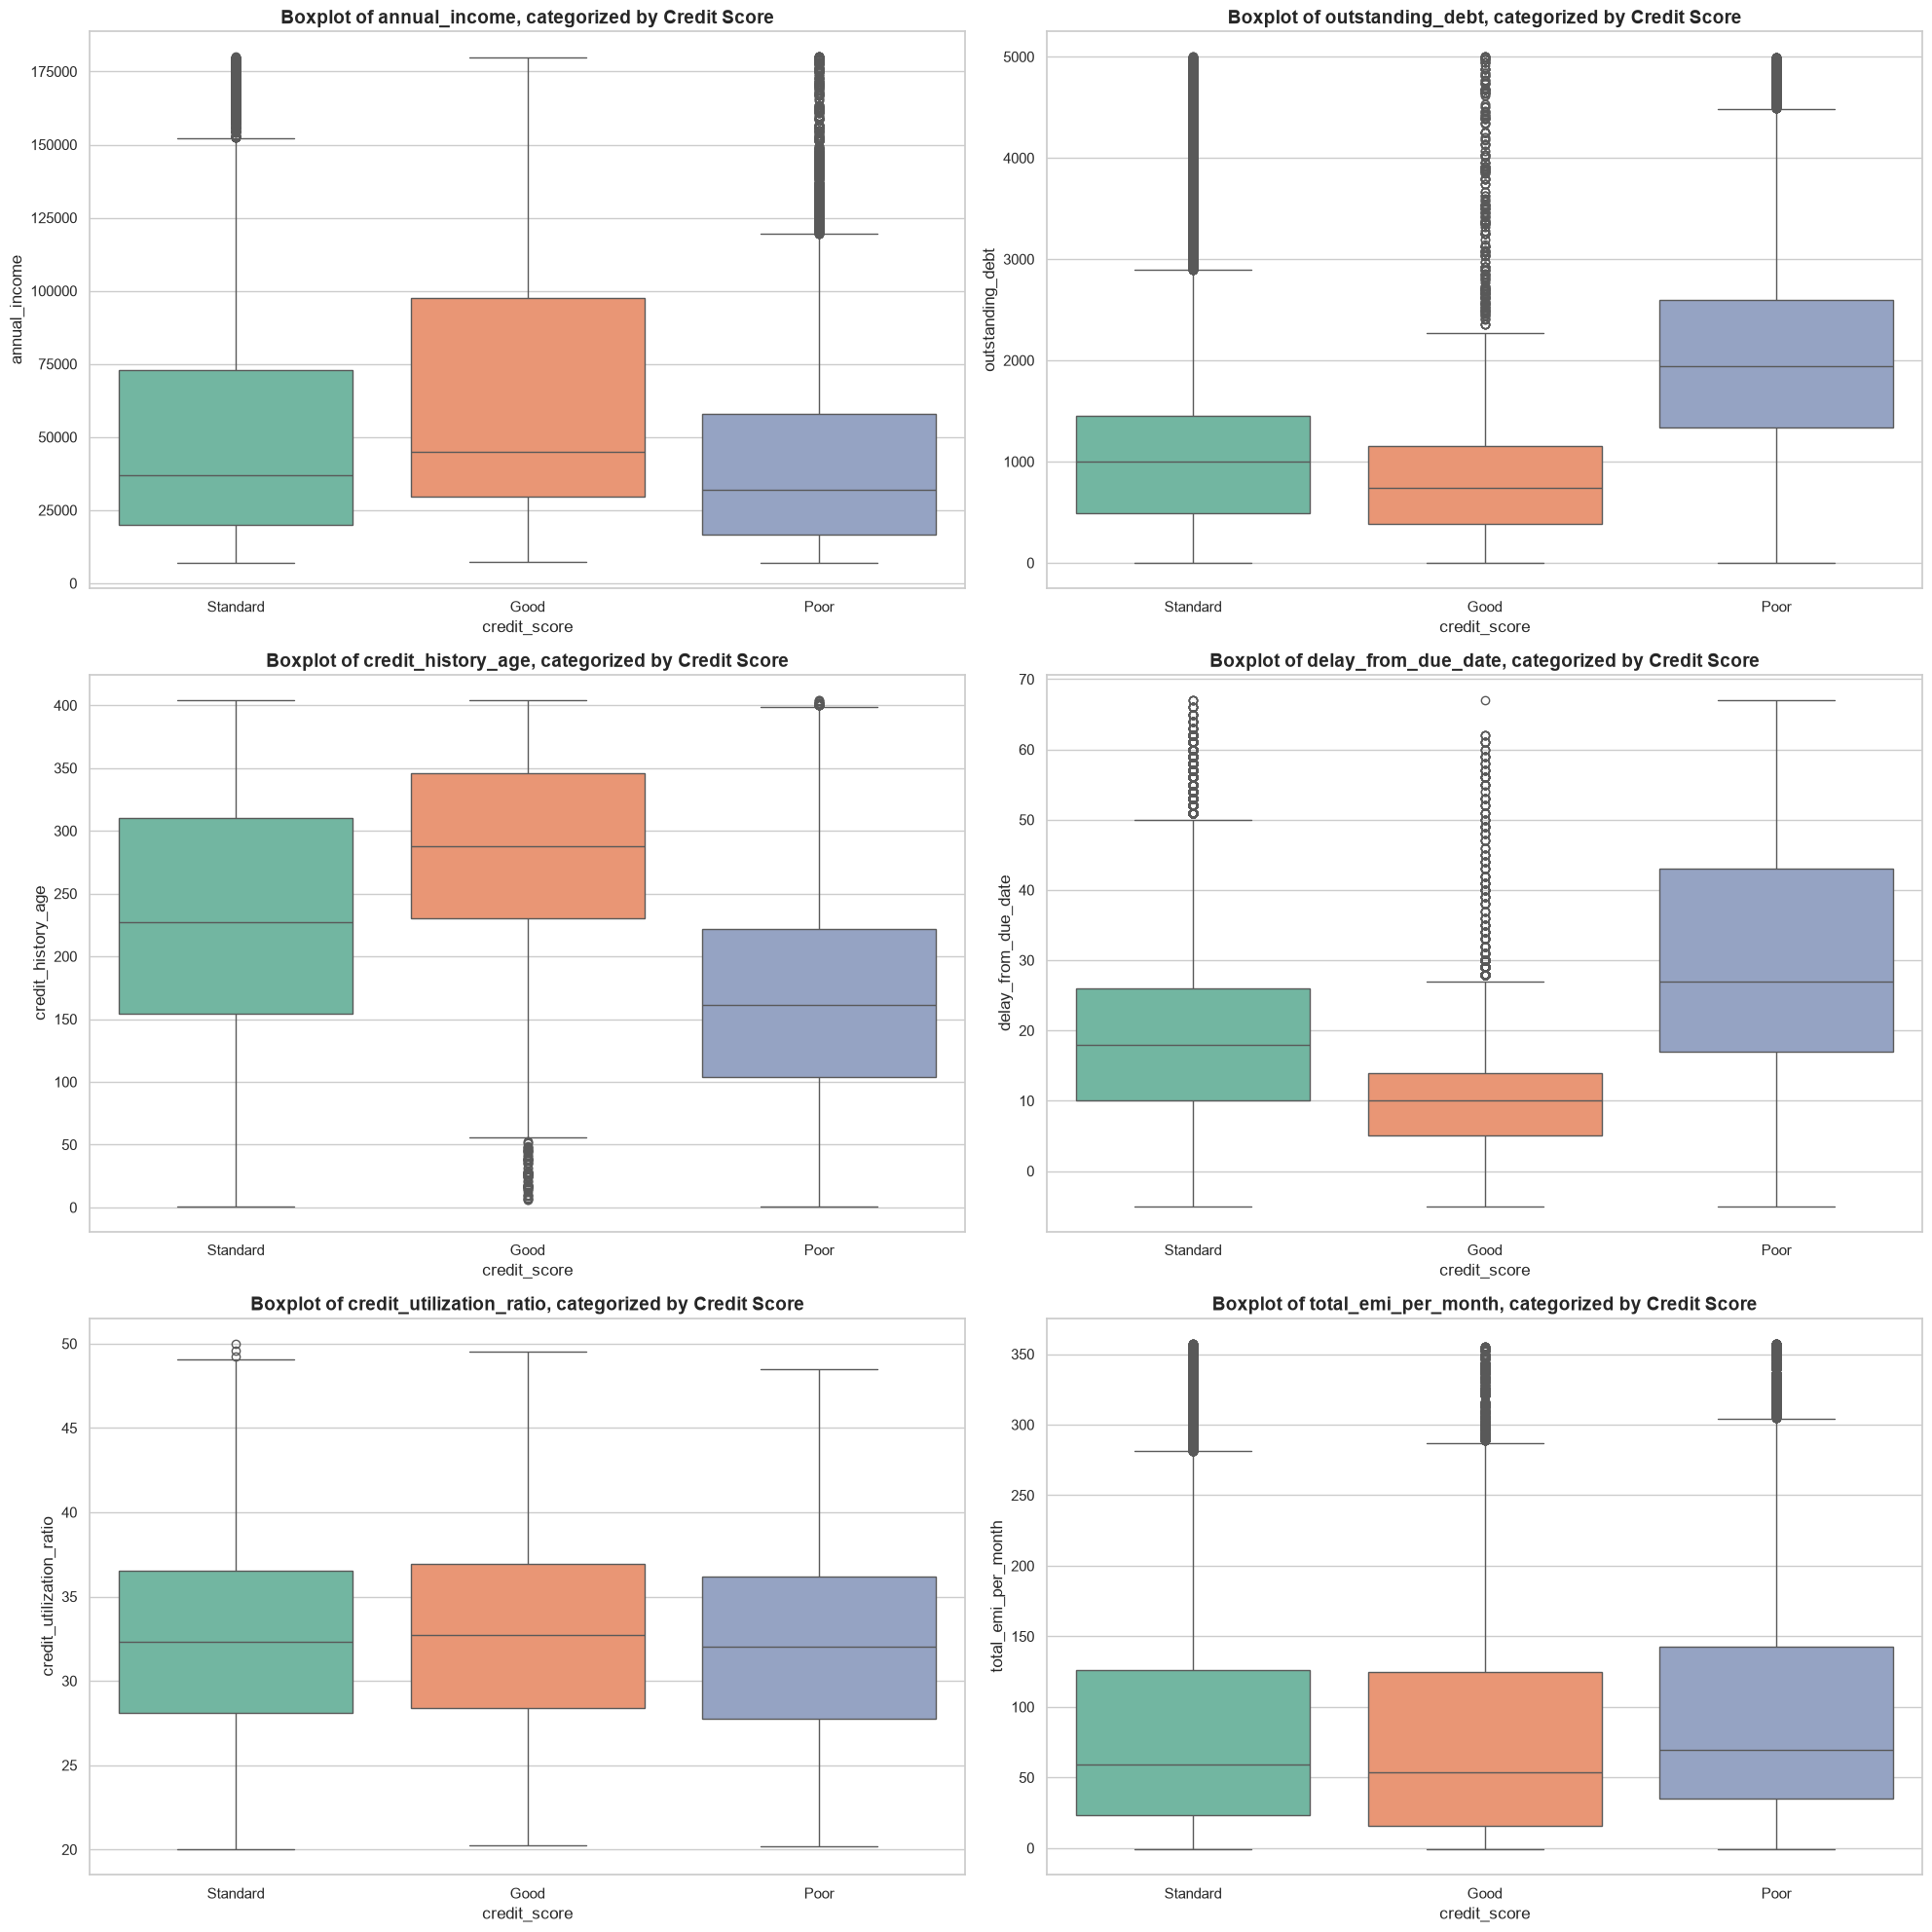

In [ ]:
boxplot_var = ['annual_income','outstanding_debt', 'credit_history_age', 'delay_from_due_date',
                'credit_utilization_ratio','total_emi_per_month']

fig, axes = plt.subplots(3, 2, figsize = (20,20))
axes = axes.flatten()

for var, ax in zip(boxplot_var, axes):
    sns.boxplot(data = df, x = 'credit_score', y = var, palette = 'Set2', hue = 'credit_score', ax = ax)
    ax.set_title(f'Boxplot of {var}, categorized by Credit Score')

plt.tight_layout()
plt.show()


In [ ]:
df = df.to_csv("my_data.csv", index=False)

## Conclusion after conducting EDA:
### Data Integrity and Class Distribution
- The dataset has no null variables or missing values.
- The target variable (`credit_score`) does not have extreme class imbalance; the "Standard" class has the highest number of records (~53.2%).
### Exploring variables
- Occupation distributions are fairly balanced across observers (ranging between 5% and 7.3% of the population), with Lawyers forming the largest group.
- `payment_of_min_amount` appears to be a major discriminator for credit scores. In the `No` group, 86.6% of observations maintain a `Standard` to `Good` credit score, with only 13.4% classified as `Poor`. However, for customers paying the minimum amount (`Yes` group), the proportion of `Good` credit scores sharply drops from 38.5% to 3.7%, while the proportion of `Poor` credit scores increases to 39.6%. This shift indicates that `payment_of_min_amount = Yes` serves as a red flag for potential credit risks.
- For payment behaviour, low-level spenders tend to make small-value payments, whereas high-level spenders mostly make medium-value payments.
- Age mostly ranges between 20 and 50 years old with a fairly equal distribution across records.
- `total_emi_per_month`, `amount_invested_monthly`, and `monthly_balance` appear right-skewed based on their histograms. Other variables exhibit multimodal distributions, which require deeper exploration using further statistical techniques or feature transformations.
- Boxplot analysis across `credit_score` classes reveals that `credit_utilization_ratio` is virtually identical across all target classes, suggesting it may have little to no predictive power for classification.
